**About this notebook**

Much of the work went into feature extraction from raw wearable signals, not only into model training. It is the cleaned-up final version, so some exploratory steps mentioned in the text are not shown in the code. All plots and outputs are kept, so you can read it without rerunning.

The first section extracts features from the raw DREAMT recordings. The raw data and the extracted feature tables are not part of this repository: download DREAMT from PhysioNet (link below), set `DREAMT_DATA_DIR` to its `data_64Hz` folder and run the feature extraction to create `features_df.csv` and `features_df_scaled.csv`. Running the whole notebook takes a long time.

# Sleep Stage Classification

In today’s fast-paced world, sleep health is more important than ever. Growing evidence links poor sleep to a range of physical and mental health issues, from reduced concentration and mood disorders to long-term chronic conditions. As awareness of sleep quality continues to rise, so does the demand for accessible and reliable tools to monitor and understand our sleep patterns.

Traditional sleep stage classification methods, like those used in sleep labs (polysomnography), are accurate but not practical for everyday users, they're expensive, time-consuming, and uncomfortable. That’s why consumer wearable devices, such as Apple Watches and fitness trackers, have started integrating sleep tracking features. These devices offer a more user-friendly and non-invasive way to collect physiological data over long periods in real-world settings.

In this project we aim to take a user-centered approach to sleep stage classification by leveraging machine learning techniques on data collected from wearable devices. Our goal is to build a model and a pipeline that can deliver accurate and meaningful insights into sleep stages from raw sensor data, helping users better understand their sleep patterns and overall health. With this project, we want to explore how far we can go in bringing reliable, personalized sleep analysis to everyone trying do distinguishing 4 sleep stages: Wake, REM, Light NREM, Deep NREM.

We want to be able to get from raw sensor data to a hypnogram plot (like the following) that as accurate as possible classifies the sleep stages for one night.

<img src="hypnogram.png" alt="Hypnogram" width="1000"/>


Predicting sleep stages from raw wearable data is a complex task that has been the focus of extensive research. It involves interpreting noisy, time-series signals such as movement and heart rate to accurately identify different stages of sleep. To guide our work, we began by reviewing a comprehensive survey paper [2], which provided an overview of the current approaches, datasets, and challenges in the field. We then identified a recent study [1] that introduced a high-quality, open-source dataset particularly well-suited to our needs. Additionally, we examined a paper focused on sleep stage classification using the Oura Ring [3], which offered valuable insights into multi-sensor integration in commercial wearables. These three papers formed the foundation for our project and informed both our data selection and modeling approach. Although deep learning techniques are currently showing very promising results in sleep stage classification from raw sensor data, we chose to focus on traditional machine learning approaches with manual feature engineering. This decision was motivated by several factors: manual feature extraction provides greater interpretability and understanding of the underlying physiological patterns, and deep learning methods typically require larger datasets than what we had available for this project.

### Data Set

For our project, we used the **DREAMT dataset** (Dataset for Real-time sleep stage EstimAtion using Multisensor wearable Technology), published in 2024 and introduced in [1]. This dataset is specifically designed for wearable-based sleep analysis and includes synchronized multisensor recordings. 

The DREAMT dataset is publicly available and can be downloaded from PhysioNet at:  
https://physionet.org/content/dreamt/2.1.0/


It includes a time-aligned collection of physiological signals recorded using the Empatica E4 wearable device, specifically designed for sleep stage analysis. All signals are synchronized and resampled to a uniform rate of **64 Hz**, ensuring precise temporal alignment across modalities—an essential requirement for effective time-series modeling.

The dataset contains both **raw signals** directly measured from the device and **derived signals** calculated from them. However, for our project, we focus exclusively on the raw signals described below.

- **TIMESTAMP:** A time vector starting at 0 seconds, sampled at 64 Hz. This guarantees that all sensor data is aligned across time for accurate feature extraction.

- **BVP:** Blood Volume Pulse, recorded via the photoplethysmography (PPG) sensor. It captures blood flow dynamics and serves as a basis for cardiovascular metrics such as heart rate and heart rate variability.

- **TEMP:** Skin temperature measured through an infrared thermopile sensor. It can provide insight into circadian phase and thermoregulation during different sleep stages.

- **ACC_X, ACC_Y, ACC_Z:** Triaxial accelerometer signals capturing body motion along three orthogonal axes. These signals are commonly used to detect movement, restlessness, and transitions between sleep and wake states.

Sleep stages in the dataset were annotated by trained technicians using gold-standard PSG (polysomnography). Labels are assigned every 30 seconds and represent the following states:

- **P:** Preparation stage — time before the PSG recording officially begins.
- **W:** Wake stage.
- **N1:** Non-REM Stage 1 — light, transitional sleep. -> Light NREM
- **N2:** Non-REM Stage 2 — deeper, stable sleep. -> Light NREM
- **N3:** Non-REM Stage 3 — deep (slow-wave) sleep. -> Deep NREM
- **R:** REM (Rapid Eye Movement) sleep — characterized by increased brain activity and vivid dreams.
- **Missing:** Indicates periods with no available PSG label.

The dataset includes overnight recordings from **100 subjects**, offering a rich source of real-world, wearable-derived sleep data. This diversity and scale make it highly suitable for developing and evaluating machine learning models aimed at sleep stage classification in out-of-clinic settings.

In [5]:
import os
import numpy as np
import pandas as pd
import neurokit2 as nk
import seaborn as sns
from scipy import signal, stats
from scipy.signal import lombscargle
from scipy.stats import mode
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, cohen_kappa_score
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings("ignore")

In [6]:
SIDS = [f"S00{i}" if i < 10 else f"S0{i}" for i in range(2, 100)]
INTERVAL_LENGTH = 30
SAMPLING_RATE = 64
OR_DF_RELEVANT_COLUMNS = ['TIMESTAMP', 'BVP', 'ACC_X', 'ACC_Y', 'ACC_Z', 'TEMP', 'Sleep_Stage']
NOT_FEATURES = ['Sleep_Stage', 'sid', "Interval"]
SLEEP_STAGE_MAPPING = {
    "N1": 2,
    "N2": 2,
    "N3": 3,
    "W": 0,
    "P": 0,
    "R": 1
}

# Feature Extraction

This part includes all the code we used to extract the features from the raw data. We extracted features from multiple physiological modalities:

- **Temperature Features**: Skin temperature statistics and variability patterns that reflect thermoregulation across sleep stages
- **PPG/Cardiovascular Features**: Heart rate and heart rate variability metrics from blood volume pulse data, including time-domain HRV (SDNN, pNN50), frequency-domain analysis (LF/HF power), and autonomic balance indicators
- **Accelerometer Features**: Movement and activity patterns from 3-axis accelerometer data (ACC_X, ACC_Y, ACC_Z), including filtered movement statistics, magnitude calculations, and movement amplitude deviation measures
- **Circadian Features**: Time-based features modeling natural sleep progression and circadian rhythm influences on sleep architecture
- **Temporal Context Features**: Rolling statistics over 5-minute windows to capture sleep stage transitions and physiological trends

We applied strict inclusion criteria to ensure data quality and balanced representation. Only subjects with complete recordings containing all sleep stages (Wake, REM, Light NREM, Deep NREM) and no missing labels were included in the analysis. Additionally, preparation stages ('P') were systematically removed from all recordings to focus exclusively on actual sleep stages and reduce class imbalance.

In [65]:
def preprocess(df):
    """
    Preprocess sleep data by removing preparation stage and segmenting into 30-second intervals.
    
    Removes 'P' (preparation) stage data, normalizes timestamps, and creates non-overlapping
    30-second intervals with exactly 1920 samples each (30s * 64Hz). Ensures each interval
    contains only one sleep stage label.
    """
    df = df.copy()
    df = df[df['Sleep_Stage'] != 'P']
    df['TIMESTAMP'] = (df['TIMESTAMP'] - df.iloc[0]["TIMESTAMP"])

    end_offset = df['TIMESTAMP'].max() % INTERVAL_LENGTH
    max_timestamp = df['TIMESTAMP'].max() - end_offset
    df = df[df['TIMESTAMP'] < max_timestamp]

    df['Interval'] = (df['TIMESTAMP'] // INTERVAL_LENGTH) * INTERVAL_LENGTH
    assert (df.groupby('Interval')['Sleep_Stage'].nunique() == 1).all(), "Multiple sleep stages in the same interval"
    assert (df.groupby('Interval').size() == INTERVAL_LENGTH * SAMPLING_RATE).all(), "Intervals must have exactly 1920 samples (30 seconds)"
    return df

In [66]:
def extract_temp_features(df_interval):
    """
    Extract temperature-based features from skin temperature sensor data.
    
    - TEMP_mean: Average skin temperature during the 30-second epoch
      * Lower temperatures often indicate deeper sleep stages
      * Temperature drops during sleep onset and deep sleep
      
    - TEMP_std: Temperature variability/stability
      * Stable temperatures suggest consolidated sleep
      * High variability may indicate sleep disturbances or transitions
    """
    temp = df_interval['TEMP']
    features = {
        'TEMP_mean': temp.mean(),
        'TEMP_std': temp.std()
    }
    return features

In [67]:
def extract_acc_features(df_interval, fs=SAMPLING_RATE):
    """
    Extract movement features from 3-axis accelerometer data.
    
    Filtered Movement Features (per axis + magnitude):
    - {AXIS}_mean: Average movement intensity after bandpass filtering
      * Wake and REM show higher values than NREM sleep
    - {AXIS}_max: Maximum movement amplitude
      * Detects significant position changes or movement events
    - {AXIS}_var: Movement variability
      * Wake: high variance, Deep sleep: low variance
    
    Movement Amplitude Deviation Features:
    - MAD_mean: Average movement amplitude deviation across 5-second windows
      * Robust measure of typical movement intensity
    - MAD_max: Maximum movement period within the epoch
      * Identifies peak activity periods
    - MAD_var: Movement pattern consistency
      * High values suggest mixed activity, low values indicate stable sleep
    """
    df_interval = df_interval.copy()

    def butter_bandpass_filter(data, lowcut=3, highcut=11, fs=SAMPLING_RATE, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = signal.butter(order, [low, high], btype='band')
        filtered = signal.filtfilt(b, a, data)
        return np.abs(filtered)

    def trimmed_mean(x, proportion=0.1):
        return stats.trim_mean(x, proportion)

    def mean_amplitude_deviation(mag):
        return np.mean(np.abs(mag - np.mean(mag)))

    features = {}
    
    # Calculate movement magnitude from 3-axis accelerometer
    df_interval["MAG"] = mag = np.sqrt(df_interval['ACC_X']**2 + df_interval['ACC_Y']**2 + df_interval['ACC_Z']**2)

    # Extract filtered movement features for each axis and magnitude
    for axis in ['ACC_X', 'ACC_Y', 'ACC_Z','MAG']:
        filtered = butter_bandpass_filter(df_interval[axis].values, fs=fs)
        features[f'{axis}_mean'] = trimmed_mean(filtered)
        features[f'{axis}_max'] = np.max(filtered)
        features[f'{axis}_var'] = np.var(filtered)

    # Calculate Movement Amplitude Deviation in 5-second sub-epochs
    samples_per_5s = fs * 5
    mad_5s = []
    
    for j in range(0, len(df_interval), samples_per_5s):
        mag_5s = mag.iloc[j:j+samples_per_5s]
        if len(mag_5s) == samples_per_5s:
            mad_5s.append(mean_amplitude_deviation(mag_5s))
        else:
            print(len(mag_5s), samples_per_5s, j, len(df_interval))

    mad_5s = np.array(mad_5s)
    features['MAD_mean'] = trimmed_mean(mad_5s)
    features['MAD_max'] = np.max(mad_5s)
    features['MAD_var'] = np.var(mad_5s)

    return features

In [68]:
def extract_ppg_features(df_interval, fs=SAMPLING_RATE):
    """
    Extract cardiovascular features from photoplethysmography (PPG) data.
    
    Basic PPG Features:
    - BVP_mean/max/min/std: Blood volume pulse signal statistics
    
    Heart Rate Features:
    - HR: Average heart rate (beats per minute)
      * Typically lowest in deep sleep, higher during REM and wake
    
    Time Domain HRV Features:
    - SDNN: Standard deviation of RR intervals
      * Measures overall autonomic activity, higher during NREM sleep
    - pNN50: Percentage of RR intervals differing by >50ms
      * Marker of parasympathetic activity, higher during deep sleep
    
    Frequency Domain HRV Features:
    - LF_Power: Low frequency power (0.04-0.15 Hz)
      * Mixed sympathetic/parasympathetic activity
    - HF_Power: High frequency power (0.15-0.4 Hz)
      * Pure parasympathetic activity marker
    - LF_HF_Ratio: Sympatho-vagal balance
      * Lower ratios indicate deep sleep, higher ratios suggest REM/wake
    - LF_Peak/HF_Peak: Dominant frequencies in each band
    """
    bvp = df_interval['BVP'].values

    features = {}

    # Basic BVP signal statistics
    features["BVP_mean"] = bvp.mean()
    features["BVP_max"] = bvp.max()
    features["BVP_min"] = bvp.min()
    features["BVP_std"] = bvp.std()

    # Heart rate and HRV extraction
    peaks_dict, _ = nk.ppg_peaks(bvp, sampling_rate=fs)
    peaks = np.where(peaks_dict["PPG_Peaks"] == 1)[0]
    peak_times = peaks / fs

    rr_intervals = np.diff(peak_times) * 1000

    # Time domain HRV features
    features['HR'] = 60000 / np.mean(rr_intervals)
    features['SDNN'] = np.std(rr_intervals)
    features['pNN50'] = np.mean(np.abs(np.diff(rr_intervals)) > 50) * 100

    # Frequency domain analysis using Lomb-Scargle periodogram
    try:
        t = np.cumsum(np.insert(rr_intervals, 0, 0)) / 1000
        t = t[:-1]
        rr_mean = np.mean(rr_intervals)
        rr_detrend = rr_intervals - rr_mean
        freqs = np.linspace(0.01, 0.5, 500)
        pxx = lombscargle(t, rr_detrend, 2 * np.pi * freqs)
        pxx /= pxx.sum() if pxx.sum() > 0 else 1

        # Define standard HRV frequency bands
        LF_band = (freqs >= 0.04) & (freqs < 0.15)
        HF_band = (freqs >= 0.15) & (freqs < 0.4)
        
        features['LF_Power'] = pxx[LF_band].sum()
        features['HF_Power'] = pxx[HF_band].sum()
        features['LF_HF_Ratio'] = features['LF_Power'] / features['HF_Power'] if features['HF_Power'] > 0 else 0
        features['LF_Peak'] = freqs[LF_band][np.argmax(pxx[LF_band])] if features['LF_Power'] > 0 else 0
        features['HF_Peak'] = freqs[HF_band][np.argmax(pxx[HF_band])] if features['HF_Power'] > 0 else 0
    except Exception:
        pass
 
    return features

In [69]:
def calculate_circadian_features(df):
    """
    Extract circadian rhythm features based on sleep progression timing.
    
    - Circadian_Cosine: Sinusoidal representation modeling sleep architecture
      * Single cycle across the entire night to capture overall sleep progression
    - Circadian_Decay: Exponential decay from sleep onset
      * Captures decreasing wake likelihood over time
    - Circadian_Linear: Linear time progression (0 to 1)
      * Simple temporal feature showing elapsed sleep duration
    """
    intervals = sorted(df['Interval'].unique())
    
    start_time = intervals[0]
    end_time = intervals[-1]
    duration = end_time - start_time
    
    norm_factor = 1.0 / duration
    
    relative_times = np.array([(interval - start_time) * norm_factor for interval in intervals])
    
    # Calculate all features in one go
    circadian_features = pd.DataFrame({
        'Circadian_Cosine': np.sin(np.pi * relative_times),
        'Circadian_Decay': np.exp(np.log(0.01) * relative_times),
        'Circadian_Linear': relative_times
    })
    
    return circadian_features

In [70]:
def roll_stats_features(df, window=5, center=True):
    """
    Generate rolling statistics to capture sleep stage transitions and temporal trends.
    
    - {feature}_rollmean_{window}_{center}: Rolling mean over time window
      * Smooths noise and captures underlying physiological trends
    - {feature}_rollvar_{window}_{center}: Rolling variance over time window  
      * Measures local stability vs variability patterns
      * Low variance suggests stable sleep, high variance indicates transitions
    """
    df_roll_stats = pd.DataFrame()
    
    cen = "prev" if not center else "cen"

    for feature in df.columns:
        df_roll_stats[f"{feature}_rollmean_{window}_{cen}"] = df[feature].rolling(
            window, min_periods=1, center=center
        ).mean()
        
        df_roll_stats[f"{feature}_rollvar_{window}_{cen}"] = df[feature].rolling(
            window, min_periods=1, center=center
        ).var()
        
    return df_roll_stats

In [71]:
def extract_all_features(df):

   interval_timestamps = sorted(df['Interval'].unique())
   
   # Extract features for each 30-second interval
   features = []
   for interval in interval_timestamps:
      interval_data = df[df['Interval'] == interval]

      features_dict = {}
      features_dict.update(extract_acc_features(interval_data))
      features_dict.update(extract_ppg_features(interval_data))
      features_dict.update(extract_temp_features(interval_data))
      features.append(features_dict)
   
   combined_features = pd.DataFrame(features)

   roll_df = roll_stats_features(combined_features, window=10)
   circ_df = calculate_circadian_features(df)

   final_df = pd.concat([combined_features, roll_df, circ_df], axis=1)

   final_df['Interval'] = df['Interval'].unique()
   final_df["Sleep_Stage"] = df.groupby('Interval')['Sleep_Stage'].first().values

   final_df = final_df.iloc[1:-1].reset_index(drop=True)

   return final_df

In [72]:
def generate_features_from_data(sids, data_path, new_file = True): 

    for sid in sids:
        try: 
            subject_path = os.path.join(data_path, f"{sid}_whole_df.csv")
            
            df = pd.read_csv(subject_path)
            df = df[OR_DF_RELEVANT_COLUMNS]

            if ('Missing' in df["Sleep_Stage"].values or 
                'R' not in df["Sleep_Stage"].values or 
                'N3' not in df["Sleep_Stage"].values):
                continue

            preprocessed_df = preprocess(df)
            subject_features = extract_all_features(preprocessed_df)
            subject_features['sid'] = sid

            # Handle NaNs - simple column mean fill
            nan_count = subject_features.isna().sum().sum()
            if nan_count > 0:
                print(f"{sid}: Found {nan_count} NaNs, filling with column means")
                for col in subject_features.columns:
                    if col not in ['sid', 'Sleep_Stage', 'Interval']:
                        subject_features[col] = subject_features[col].fillna(subject_features[col].mean())

            if new_file:
                subject_features.to_csv('features_df.csv', index=False)
                new_file = False
            else:
                subject_features.to_csv('features_df.csv', mode='a', header=False, index=False)
        except Exception as e:
            print(f"Error processing {sid}: {e}")
            continue
        
    return pd.read_csv('features_df.csv')

In [73]:
import os
data_path = os.environ.get("DREAMT_DATA_DIR", "data/dreamt/2.1.0/data_64Hz")
# df = generate_features_from_data(SIDS, data_path, new_file = True)
# df.head()

## Normalize and scale features

In [74]:
def norm_and_scale_features_per_subject(df):

    feature_columns = [col for col in df.columns if col not in NOT_FEATURES and df[col].dtype.kind in 'bifc']
    
    df_scaled = df.copy()
    
    for sid in df['sid'].unique():
        mask = df['sid'] == sid
        subject_data = df.loc[mask, feature_columns].copy()
        
        # Step 1: Normalize each column with 5-95 percentiles for this subject
        for col in feature_columns:
            p5, p95 = subject_data[col].quantile([0.05, 0.95])
            if p95 != p5:  # Avoid division by zero
                subject_data[col] = (subject_data[col] - p5) / (p95 - p5)
        
        # Step 2: StandardScale all features for this subject
        scaler = StandardScaler()
        subject_data_scaled = scaler.fit_transform(subject_data)
        
        df_scaled.loc[mask, feature_columns] = subject_data_scaled
        
    return df_scaled

In [75]:
# df = pd.read_csv('features_df.csv')
# df_scaled = norm_and_scale_features_per_subject(df)
# df_scaled.to_csv('features_df_scaled.csv', index=False)

## Visualize features and sleep stages

In this part we visualize some features to get a feeling for how the data looks like and how predcitive they might be.

In [54]:
def plot_hypnogram(labels, time, figsize=(12, 5)):

    colors = {
        0: "#ffffff",     # Awake (white)
        1: "#c8e0f5",     # REM (approx)
        2: "#5eaede",     # Light (approx)
        3: "#0278bd"      # Deep (approx)
        }
    background_color = "#0A3C5F"

    stage_mapping = {0: 3, 1: 2, 2: 1, 3: 0}  # Map stages to vertical positions

    cmap = LinearSegmentedColormap.from_list('SleepBlue', list(colors.values())[::-1])

    # Calculate percentages for each sleep stage
    total_labels = len(labels)
    stage_percentages = {stage: (labels.count(stage) / total_labels) * 100 for stage in stage_mapping.keys()}

    # Convert labels to numeric stages and prepare timestamps
    numeric_stages = [stage_mapping.get(stage, 0) for stage in labels]
    timestamps = [t / 60 for t in time]  # Convert time to hours

    height = 0.3

    fig, ax = plt.subplots(figsize=figsize, dpi=120, facecolor=background_color)  # Lighter blue background
    ax.set_facecolor(background_color)


    # Iterate through intervals and draw vertical lines
    for i in range(len(numeric_stages) - 1):
        x = timestamps[i]
        y_start = numeric_stages[i]
        y_end = numeric_stages[i + 1]

        # Check if it's a transition interval
        if y_start != y_end:
            # Smooth colormap transition for transitions
            n_points = 200
            if y_start < y_end:
                y_bottom = y_start + height
                y_top = y_end - height
            else:
                y_bottom = y_end + height
                y_top = y_start - height

            y_points = np.linspace(y_bottom, y_top, n_points)  # Adjusted to draw from end to end
            x_points = np.linspace(x, x, n_points)  # Transition starts and ends at the same x position

            # Create segments for the line
            points = np.array([x_points, y_points]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]], axis=1)

            # Color the line based on its vertical position
            segment_colors = [cmap(y / 4) for y in y_points[:-1]]

            lc = LineCollection(
                segments,
                colors=segment_colors,
                linewidth=1.5,
                alpha=1,
                antialiased=False,
                zorder=1
            )
            ax.add_collection(lc)

            ax.plot(
                [x, x],
                [y_end - height, y_end + height],
                color=cmap(y_end / 4),
                linewidth=2,
                alpha=1,
                zorder=3
            )

        # Single-colored line for non-transition intervals
        ax.plot(
            [x, x],
            [y_start - height, y_start + height],
            color=cmap(y_start / 4),
            linewidth=2,
            alpha=1,
            zorder=3
        )

    # Add white dotted lines for each stage
    for y in [0, 1, 2, 3]:
        ax.axhline(y, color='white', linestyle='--', linewidth=0.5, alpha=0.8, zorder=0)

    # Set axis limits and labels
    ax.set_ylim(-0.5, 3.5)
    ax.set_xlim(timestamps[0], timestamps[-1])

    # Create y-axis labels with percentages and color them
    y_labels = []
    for stage, y_pos in stage_mapping.items():
        percentage = stage_percentages.get(y_pos, 0)
        label = f"{['Deep', 'Light', 'REM', 'Awake'][stage]}\n{percentage:.1f}%"
        y_labels.append(label)
    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(y_labels, fontsize=12, color='white', fontweight='400')

    ax.tick_params(axis='y', pad=20, length=0, colors='white')
    # Convert x-axis to hours
    start_hour = int(timestamps[0] // 60)
    end_hour = int(timestamps[-1] // 60) + 1

    # Correct range step is 1 (one hour per tick)
    hours = list(range(start_hour, end_hour))
    hour_ticks = [hour * 60 for hour in hours]
    hour_labels = [f"{hour}:00h" for hour in hours]

    ax.set_xticks(hour_ticks)
    ax.set_xticklabels(hour_labels, fontsize=11, color='white')
    ax.tick_params(axis='x', colors='white', length=0)
    ax.set_xlabel('Time (hours)', fontsize=11, color='white', labelpad=10)

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(left=0.12, top=0.92)
    plt.show()

In [77]:
def plot_feature(df, feature, bin_minutes=0.5, sleep_stage_col='Sleep_Stage', time_col='Interval'):

    colors = {
        0: "#05d9b5",    # WAKE - cyan
        1: '#fb8072',    # REM - red  
        2: "#1f2990",    # LIGHT NREM (N1/N2) - light yellow
        3: "#81c5ea",    # DEEP NREM (N3) - dark blue
        np.nan: '#cccccc' # Unknown - light gray
    }
    stage_names = {
        0: 'WAKE',
        1: 'REM',
        2: 'LIGHT NREM',
        3: 'DEEP NREM',
        np.nan: 'UNKNOWN'
    }

    # Sort and bin
    sorted_df = df.sort_values(time_col).copy()
    sorted_df['Minutes'] = (sorted_df[time_col] - sorted_df[time_col].min()) / 60
    bin_size_sec = bin_minutes * 60
    sorted_df['Time_Bin'] = (sorted_df[time_col] // bin_size_sec) * bin_size_sec
    sorted_df['Bin_Minutes'] = (sorted_df['Time_Bin'] - sorted_df[time_col].min()) / 60

    binned_data = sorted_df.groupby('Bin_Minutes').agg({
        feature: 'mean',
        sleep_stage_col: lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    }).reset_index()

    # Set background
    plt.style.use('default')
    fig, ax = plt.subplots(figsize=(12, 5), facecolor='#f5f5f5')
    ax.set_facecolor('#f5f5f5')

    # Line segments colored by sleep stage
    points = np.array([binned_data['Bin_Minutes'].values, binned_data[feature].values]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    segment_colors = [colors.get(binned_data[sleep_stage_col].iloc[j], '#cccccc') for j in range(len(segments))]
    lc = LineCollection(segments, colors=segment_colors, linewidth=2, zorder=2)
    ax.add_collection(lc)

    # Optionally add a black edge for contrast
    lc_edge = LineCollection(segments, colors='black', linewidth=0.5, zorder=1)
    ax.add_collection(lc_edge)

    ax.autoscale()
    ax.set_xlim(binned_data['Bin_Minutes'].min(), binned_data['Bin_Minutes'].max())

    # Labels and grid
    ax.set_title(f"{feature.replace('_', ' ').title()}", fontsize=16)
    ax.set_xlabel('Time (minutes)', fontsize=13)
    ax.set_ylabel('bpm' if 'hr' in feature.lower() else 'Value', fontsize=13)
    ax.grid(True, color='white', linewidth=1.2, alpha=1, zorder=0)

    # Simple legend - updated for 4 stages
    unique_stages = [stage for stage in [0, 1, 2, 3] if stage in binned_data[sleep_stage_col].unique()]
    legend_patches = [Patch(color=colors[stage], label=stage_names[stage]) for stage in unique_stages]
    ax.legend(handles=legend_patches, fontsize=12)

    plt.tight_layout()
    plt.show()

In [78]:
df = pd.read_csv('features_df.csv')
df_s = df[df['sid'] == 'S011'].copy()
df_s["Sleep_Stage"] = df_s["Sleep_Stage"].map(SLEEP_STAGE_MAPPING)

In [ ]:
plot_hypnogram(df_s["Sleep_Stage"].values.tolist(), df_s["Interval"].values.tolist())

In [ ]:
circadian_features = [
    'Circadian_Decay',
    'Circadian_Cosine',
    'Circadian_Linear'
]

for feat in circadian_features:
    plot_feature(df=df_s, feature=feat, bin_minutes=0.5)

In [ ]:
features = [
    'HR',
    "HR_rollmean_10_cen",
    "HR_rollvar_10_cen",
]

for feat in features:
    plot_feature(df=df_s, feature=feat, bin_minutes=0.5)

In [ ]:
features = [
    'MAD_mean',
    "MAD_mean_rollmean_10_cen",
    "MAD_mean_rollvar_10_cen",
]

for feat in features:
    plot_feature(df=df_s, feature=feat, bin_minutes=0.5)

## Feature Correlation

In [83]:
df_scaled = pd.read_csv('features_df_scaled.csv')

In [84]:
df_scaled['Sleep_Stage'] = df_scaled['Sleep_Stage'].map(SLEEP_STAGE_MAPPING)

correlations = {}
for feature in df_scaled.columns:
    if feature not in NOT_FEATURES:
        corr = abs(df_scaled[feature].corr(df_scaled['Sleep_Stage']))
        correlations[feature] = corr

top_20_correlated = sorted(correlations.items(), key=lambda x: x[1], reverse=True)[:20]

print("Top 20 features most correlated with sleep stages:")
print("="*50)
print(f"{'Feature':<40} | {'Correlation':<10}")
print("-"*50)
for i, (feature, corr) in enumerate(top_20_correlated):
    print(f"{i+1:2d}. {feature:<37} | {corr:.4f}")

Top 20 features most correlated with sleep stages:
Feature                                  | Correlation
--------------------------------------------------
 1. ACC_X_max_rollmean_10_cen             | 0.3670
 2. MAG_max_rollmean_10_cen               | 0.3637
 3. MAD_max_rollmean_10_cen               | 0.3615
 4. ACC_Z_max_rollmean_10_cen             | 0.3594
 5. ACC_Y_max_rollmean_10_cen             | 0.3456
 6. BVP_max_rollmean_10_cen               | 0.3287
 7. BVP_min_rollmean_10_cen               | 0.3267
 8. MAD_mean_rollmean_10_cen              | 0.3265
 9. ACC_X_var_rollmean_10_cen             | 0.3232
10. MAG_var_rollmean_10_cen               | 0.3182
11. ACC_Z_var_rollmean_10_cen             | 0.3155
12. MAD_var_rollmean_10_cen               | 0.3099
13. HR_rollvar_10_cen                     | 0.3096
14. ACC_Z_mean_rollmean_10_cen            | 0.3076
15. ACC_X_max_rollvar_10_cen              | 0.3048
16. ACC_Y_var_rollmean_10_cen             | 0.3044
17. BVP_std_rollvar_10_cen 

In [85]:
# Find highly correlated feature pairs
exclude_cols = NOT_FEATURES + ['Sleep_Stage_Numeric']
feature_columns = [col for col in df_scaled.columns if col not in exclude_cols]

# Calculate correlation matrix
corr_matrix = df_scaled[feature_columns].corr().abs()

# Get upper triangle of correlation matrix (to avoid duplicates)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find pairs above threshold
threshold = 0.8
high_corr_pairs = upper_tri.stack().reset_index()
high_corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']
high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'] > threshold].sort_values('Correlation', ascending=False)

print(f"Feature pairs with correlation > {threshold}:")
print("="*70)
print(f"{'Feature 1':<35} | {'Feature 2':<35} | {'Correlation':<10}")
print("-"*70)
for _, row in high_corr_pairs.head(20).iterrows():
    print(f"{row['Feature1']:<35} | {row['Feature2']:<35} | {row['Correlation']:.4f}")

print(f"\nTotal highly correlated pairs: {len(high_corr_pairs)}")
print(f"Total features: {len(feature_columns)}")

Feature pairs with correlation > 0.8:
Feature 1                           | Feature 2                           | Correlation
----------------------------------------------------------------------
TEMP_mean                           | TEMP_mean_rollmean_10_cen           | 0.9888
ACC_Z_mean_rollvar_10_cen           | MAG_mean_rollvar_10_cen             | 0.9797
ACC_X_mean_rollvar_10_cen           | ACC_Z_mean_rollvar_10_cen           | 0.9782
ACC_X_mean_rollvar_10_cen           | MAG_mean_rollvar_10_cen             | 0.9749
ACC_Z_max_rollmean_10_cen           | MAG_max_rollmean_10_cen             | 0.9732
ACC_Z_var_rollmean_10_cen           | MAG_var_rollmean_10_cen             | 0.9686
ACC_X_max_rollmean_10_cen           | MAG_max_rollmean_10_cen             | 0.9668
MAG_mean_rollmean_10_cen            | MAD_mean_rollmean_10_cen            | 0.9667
ACC_X_max_rollmean_10_cen           | ACC_Z_max_rollmean_10_cen           | 0.9657
ACC_X_var_rollmean_10_cen           | ACC_Z_var_rollmean

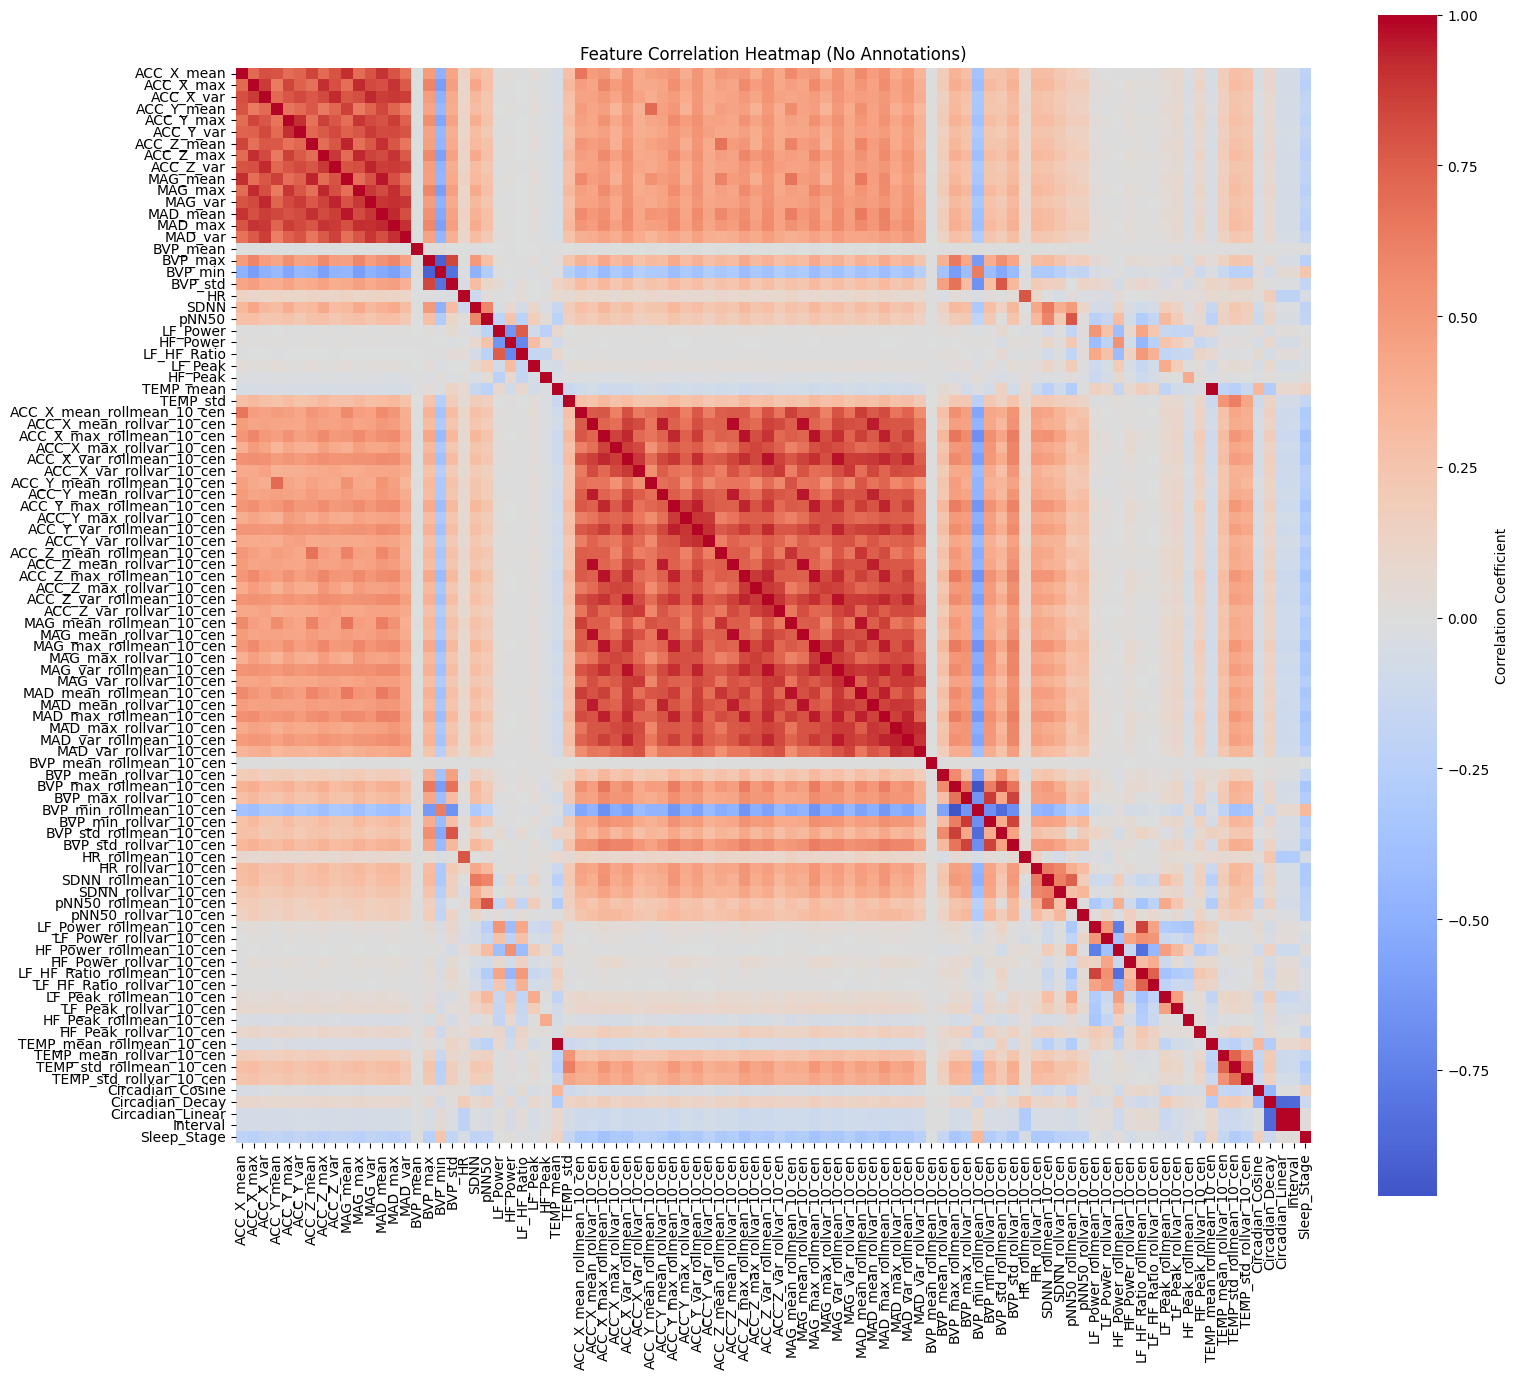

In [87]:
corr = df_scaled.corr(numeric_only=True)

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'label': 'Correlation Coefficient'},
            xticklabels=True, yticklabels=True, annot=False)

plt.title("Feature Correlation Heatmap (No Annotations)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In this part, we extracted features from the raw data, focusing on commonly used signals in sleep stage classification. Our goal was to reduce the feature set to the essential minimum needed for accurate modeling. This turned out to be the most time-consuming part of the project, involving a lot of trial and error to strike a balance between informativeness and simplicity. Although we're not fully satisfied with the final set, we believe it offers a solid foundation for modeling.

The correlation analysis revealed expected patterns: accelerometer axes were strongly correlated, heart rate features clustered together, and rolling features correlated with their base values. Importantly, rolling statistics consistently showed stronger correlations with sleep stages than single-epoch features—highlighting the importance of capturing temporal context rather than relying on isolated intervals.

We found many highly correlated feature pairs (correlation > 0.8), including many cases where temperature or movement values were very similar to their rolling averages. While we had already removed several redundant features earlier, we decided to keep the remaining correlated ones for practical reasons. What looks redundant on paper may still offer distinct value for classification. In addition, tree-based models like Random Forest and LightGBM are well-suited to handle feature redundancy and can naturally select the most relevant signals during training. Removing features purely based on correlation risked discarding meaningful physiological information—like the complementary roles of heart rate and its rolling mean.

Ultimately, while the feature set is larger than strictly necessary, this approach gives the models room to find the best combination of predictors. The process highlighted the value of temporal features and raised questions about redundancy that we may address later through feature selection or dimensionality reduction. For now, we’re confident that this engineered feature set provides a strong starting point for building sleep stage prediction models.


# Classification 

With the features extracted in the previous section, we now move on to building a sleep stage classification model. This follows a fairly standard machine learning pipeline, where the goal is to predict one of four stages (Wake, REM, Light NREM, or Deep NREM) for each interval.

However, evaluating performance in sleep staging isn’t straightforward. While accuracy is important, it can be misleading due to class imbalance—especially because Light NREM dominates most nights. A model could achieve decent accuracy by simply over-predicting the majority class. To avoid this, we used Cohen’s kappa and the F1 score as our primary metric. 

We started by taking LGBM as a baseline model to eyplore different variations. With more improved features we did a model comparison to see which model works best. The best model was then fine tuned and used for final predictions. The final predictions where further postprocessed and smoothed to better align with real sleep data.

We also explored ensmbles and different optimization objectives but narrowed down on using simple classifiers with standard optimization criteria.

In [2]:
import xgboost as xgb
import catboost as cb
import joblib
import shap

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier

In [60]:
df = pd.read_csv('features_df_scaled.csv')

In [ ]:
df

In [62]:
df.isna().sum().sum()

0

In [63]:
df["Sleep_Stage"].unique()

array(['W', 'N1', 'N2', 'N3', 'R'], dtype=object)

In [64]:
df["Sleep_Stage"] = df["Sleep_Stage"].map(SLEEP_STAGE_MAPPING)
df["Sleep_Stage"] = df["Sleep_Stage"].astype(int)

In [65]:
df['Sleep_Stage'].value_counts()

Sleep_Stage
2    19437
0     5988
1     3738
3     2295
Name: count, dtype: int64

### Training & helper functions

To train and evalualte the models we used those functions. Especially focussing on keeping subjects seperated, meaning subjects which we wanted to use to test are not included in the training data to test generlizability. We chose a stratified group k fold approach following literature.

In [69]:
def sgkf(model, data, n_splits=5, show_eval=True):

    features = data[data.columns.difference(NOT_FEATURES)]
    groups = data["sid"]
    labels = data["Sleep_Stage"]

    sgkf = StratifiedGroupKFold(n_splits=n_splits)

    all_predictions, all_true_labels = [], []

    for fold, (train_idx, test_idx) in enumerate(sgkf.split(features, labels, groups)):
        X_train, X_test = features.iloc[train_idx], features.iloc[test_idx]
        y_train, y_test = labels.iloc[train_idx], labels.iloc[test_idx]

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        all_predictions.extend(y_pred)
        all_true_labels.extend(y_test)

        if show_eval:
            kappa = cohen_kappa_score(y_test, y_pred)
            print(f"Fold: {fold+1}/{n_splits} - Cohen's Kappa: {kappa:.4f}")

    return all_true_labels, all_predictions, model

In [70]:
def visualize_performance(y_true, y_pred):   
    kappa = cohen_kappa_score(y_true, y_pred)
    print("Cohen's Kappa:", kappa) 
    print(classification_report(y_true, y_pred, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

In [71]:
def plot_feature_importance(model, feature_names, top_n=20):

    importances = (model.feature_importances_ / model.feature_importances_.sum()) * 100
    
    if top_n > 0:
        indices = np.argsort(importances)[::-1][:top_n]
    else:
        indices = np.argsort(importances)[::-1][top_n:]
    
    plt.figure(figsize=(8, 6))
    plt.barh(range(abs(top_n)), importances[indices])
    plt.yticks(range(abs(top_n)), [feature_names[i] for i in indices])
    plt.xlabel('Feature Importance (%)')
    plt.title(f'Top {top_n} Feature Importances')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## Exploration

We started with exploring the performance usig a lgbm as it is tree based which we expected to be good, fast to train and most important succesfully used in literature [2]. We also used this as a base line for further model exploration. As the data set is quite large we reduced it to only the first 20 subject, which makes it less robust and dependent on the subjects used to test but should still serve as a meaningfull set for exploration.

In [66]:
print(df["sid"].nunique())

unique_sids = df['sid'].unique()[:20]
df_explore = df[df['sid'].isin(unique_sids)].copy()

print(df_explore["sid"].nunique())
print(df_explore.shape)

39
20
(16132, 93)


In [67]:
lgbm_model = LGBMClassifier(
    objective='multiclass',  # Use standard multiclass for stability
    metric='multi_logloss',  # Standard metric
    n_estimators=200,
    max_depth=20,
    learning_rate=0.05,
    class_weight='balanced',
    verbosity=-1,    
    random_state=42,
)

Fold: 1/5 - Cohen's Kappa: 0.3200
Fold: 2/5 - Cohen's Kappa: 0.2346
Fold: 3/5 - Cohen's Kappa: 0.3063
Fold: 4/5 - Cohen's Kappa: 0.1751
Fold: 5/5 - Cohen's Kappa: 0.3961
Cohen's Kappa: 0.2858528098416818
              precision    recall  f1-score   support

           0       0.53      0.57      0.55      5988
           1       0.32      0.23      0.26      3738
           2       0.69      0.76      0.72     19437
           3       0.42      0.23      0.30      2295

    accuracy                           0.62     31458
   macro avg       0.49      0.45      0.46     31458
weighted avg       0.60      0.62      0.61     31458



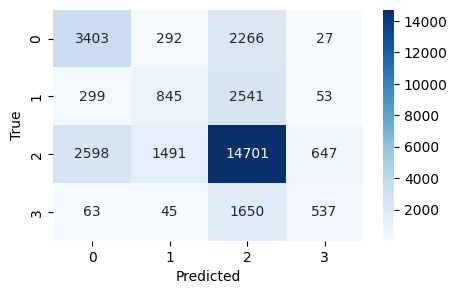

In [72]:
y_true_baseline, y_pred_baseline, baseline_model = sgkf(lgbm_model, df, show_eval=True)
visualize_performance(y_true_baseline, y_pred_baseline)

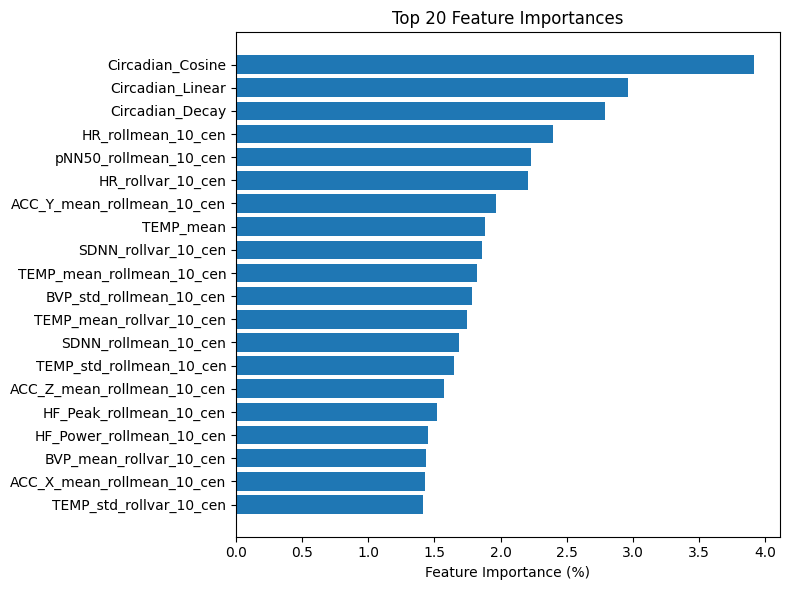

In [73]:
plot_feature_importance(baseline_model, df.columns.difference(NOT_FEATURES).tolist())

### PCA
We used Principal Component Analysis (PCA) to visualize the data's main patterns. This helps us see if our model might be using unnecessary features (which would make it more prone to overfitting) or missing important ones (which means additional features helps the model - underfitting).


=== Testing PCA with 50 components ===
Fold: 1/5 - Cohen's Kappa: 0.2101
Fold: 2/5 - Cohen's Kappa: 0.1761
Fold: 3/5 - Cohen's Kappa: 0.2184
Fold: 4/5 - Cohen's Kappa: 0.3032
Fold: 5/5 - Cohen's Kappa: 0.2739
Cohen's Kappa: 0.23518354721431467
              precision    recall  f1-score   support

           0       0.45      0.56      0.50      2640
           1       0.30      0.26      0.28      2155
           2       0.68      0.68      0.68      9952
           3       0.33      0.24      0.28      1385

    accuracy                           0.57     16132
   macro avg       0.44      0.44      0.43     16132
weighted avg       0.56      0.57      0.56     16132



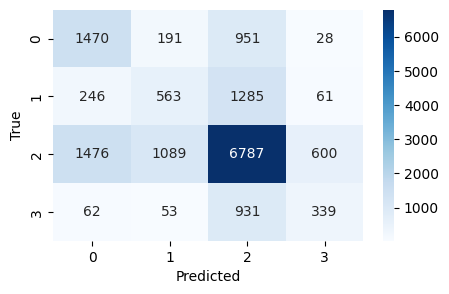


Baseline Kappa: 0.2859, F1 Macro: 0.4602
PCA Kappa: 0.2352, F1 Macro: 0.4349


In [102]:
def apply_pca_analysis(df, n_components=50):
    """Apply PCA with specified number of components and evaluate performance"""
    
    print(f"\n=== Testing PCA with {n_components} components ===")
    
    # Create pipeline with PCA
    pca_model = Pipeline([
        ('pca', PCA(n_components=n_components, random_state=42)),
        ('classifier', LGBMClassifier(
            objective='multiclass',
            n_estimators=200,
            max_depth=20,
            learning_rate=0.05,
            class_weight='balanced',
            verbosity=-1,
            random_state=42
        ))
    ])
    
    # Test with cross-validation
    y_true_pca, y_pred_pca, _ = sgkf(pca_model, df, show_eval=True)
    
    # Calculate performance metrics
    kappa = cohen_kappa_score(y_true_pca, y_pred_pca)
    f1_macro = f1_score(y_true_pca, y_pred_pca, average='macro')

    return {
        'kappa': kappa,
        'f1_macro': f1_macro,
        'y_true': y_true_pca,
        'y_pred': y_pred_pca
    }

pca_result = apply_pca_analysis(df_explore, n_components=50)

# Compare with baseline
baseline_kappa = cohen_kappa_score(y_true_baseline, y_pred_baseline)
baseline_f1 = f1_score(y_true_baseline, y_pred_baseline, average='macro')
visualize_performance(pca_result['y_true'], pca_result['y_pred'])
print(f"\nBaseline Kappa: {baseline_kappa:.4f}, F1 Macro: {baseline_f1:.4f}")
print(f"PCA Kappa: {pca_result['kappa']:.4f}, F1 Macro: {pca_result['f1_macro']:.4f}")

The model doesn't benefit from simplification because each feature contributes important information. This points toward underfitting, or struggling to capture enough structure from the  data

### Add more temporal features to give context

In [11]:
def temporal_context_features(df):
    """Add temporal context features to help with sleep stage transitions"""
    
    df_temporal = df.copy()
    
    for col in ['HR', 'SDNN', 'MAD_mean', 'BVP_mean', 'TEMP_mean']:  # Key features only
        if col in df.columns:
            # Previous values (what happened before)
            df_temporal[f"{col}_prev_1"] = df[col].shift(1)
            df_temporal[f"{col}_prev_2"] = df[col].shift(2)
            
            # Future values (what's coming next) 
            df_temporal[f"{col}_next_1"] = df[col].shift(-1)
            
            # Trend features
            df_temporal[f"{col}_trend"] = df[col] - df[col].shift(1)
            df_temporal[f"{col}_acceleration"] = df_temporal[f"{col}_trend"] - df_temporal[f"{col}_trend"].shift(1)
    
    # Fill NaN values
    df_temporal = df_temporal.fillna(method='bfill').fillna(method='ffill')
    
    return df_temporal

In [104]:
df_temporal = temporal_context_features(df)
print(f"Enhanced dataset shape: {df_temporal.shape}")

Enhanced dataset shape: (31458, 118)


Fold: 1/5 - Cohen's Kappa: 0.3239
Fold: 2/5 - Cohen's Kappa: 0.2215
Fold: 3/5 - Cohen's Kappa: 0.3245
Fold: 4/5 - Cohen's Kappa: 0.1956
Fold: 5/5 - Cohen's Kappa: 0.4059
Cohen's Kappa: 0.2933514072722412
              precision    recall  f1-score   support

           0       0.54      0.57      0.55      5988
           1       0.34      0.25      0.29      3738
           2       0.70      0.76      0.73     19437
           3       0.42      0.23      0.30      2295

    accuracy                           0.62     31458
   macro avg       0.50      0.45      0.47     31458
weighted avg       0.60      0.62      0.61     31458



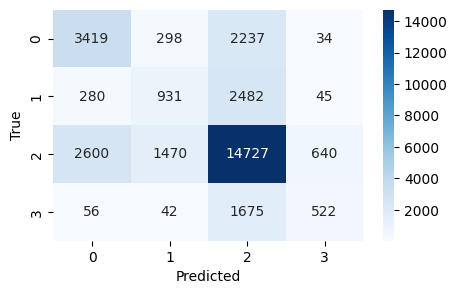

In [107]:
y_true_baseline, y_pred_baseline, baseline_model = sgkf(lgbm_model, df_temporal, show_eval=True)
visualize_performance(y_true_baseline, y_pred_baseline)

# Model comparison

We tested the performance of different models on the reduced dataset to choose the best for finetuning and final training.

In [108]:
# Test 1: Random Forest
print("Testing Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

y_true_rf, y_pred_rf, _ = sgkf(rf_model, df, show_eval=True)
kappa_rf = cohen_kappa_score(y_true_rf, y_pred_rf)
f1_rf = f1_score(y_true_rf, y_pred_rf, average='macro')

print(f"\nRandom Forest Results:")
print(f"Cohen's Kappa: {kappa_rf:.4f}")
print(f"F1-Score (macro): {f1_rf:.4f}")

Testing Random Forest...
Fold: 1/5 - Cohen's Kappa: 0.2214
Fold: 2/5 - Cohen's Kappa: 0.2109
Fold: 3/5 - Cohen's Kappa: 0.2219
Fold: 4/5 - Cohen's Kappa: 0.1409
Fold: 5/5 - Cohen's Kappa: 0.3093

Random Forest Results:
Cohen's Kappa: 0.2229
F1-Score (macro): 0.3582


In [109]:
# Test 2: Extra Trees
print("Testing Extra Trees...")
et_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

y_true_et, y_pred_et, _ = sgkf(et_model, df, show_eval=True)
kappa_et = cohen_kappa_score(y_true_et, y_pred_et)
f1_et = f1_score(y_true_et, y_pred_et, average='macro')

print(f"\nExtra Trees Results:")
print(f"Cohen's Kappa: {kappa_et:.4f}")
print(f"F1-Score (macro): {f1_et:.4f}")

Testing Extra Trees...
Fold: 1/5 - Cohen's Kappa: 0.2363
Fold: 2/5 - Cohen's Kappa: 0.1934
Fold: 3/5 - Cohen's Kappa: 0.2041
Fold: 4/5 - Cohen's Kappa: 0.1460
Fold: 5/5 - Cohen's Kappa: 0.3041

Extra Trees Results:
Cohen's Kappa: 0.2179
F1-Score (macro): 0.3380


In [ ]:
# Test 3: XGBoost 
print("Testing XGBoost...")
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    n_estimators=200,
    max_depth=15,
    learning_rate=0.05,
    random_state=42,
    eval_metric='mlogloss',
    verbosity=0
)

y_true_xgb, y_pred_xgb, _ = sgkf(xgb_model, df, show_eval=True)
kappa_xgb = cohen_kappa_score(y_true_xgb, y_pred_xgb)
f1_xgb = f1_score(y_true_xgb, y_pred_xgb, average='macro')

print(f"\nXGBoost Results:")
print(f"Cohen's Kappa: {kappa_xgb:.4f}")
print(f"F1-Score (macro): {f1_xgb:.4f}")

Testing XGBoost...
Fold: 1/5 - Cohen's Kappa: 0.2590
Fold: 2/5 - Cohen's Kappa: 0.2166
Fold: 3/5 - Cohen's Kappa: 0.2291
Fold: 4/5 - Cohen's Kappa: 0.1950
Fold: 5/5 - Cohen's Kappa: 0.3446

XGBoost Results:
Cohen's Kappa: 0.2495
F1-Score (macro): 0.3723


In [111]:
# Test 4: CatBoost 
print("Testing CatBoost...")
cat_model = cb.CatBoostClassifier(
    iterations=200,
    depth=8,
    learning_rate=0.05,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=False
)

y_true_cat, y_pred_cat, _ = sgkf(cat_model, df, show_eval=True)
kappa_cat = cohen_kappa_score(y_true_cat, y_pred_cat)
f1_cat = f1_score(y_true_cat, y_pred_cat, average='macro')

print(f"\nCatBoost Results:")
print(f"Cohen's Kappa: {kappa_cat:.4f}")
print(f"F1-Score (macro): {f1_cat:.4f}")

Testing CatBoost...
Fold: 1/5 - Cohen's Kappa: 0.3402
Fold: 2/5 - Cohen's Kappa: 0.2317
Fold: 3/5 - Cohen's Kappa: 0.3022
Fold: 4/5 - Cohen's Kappa: 0.1946
Fold: 5/5 - Cohen's Kappa: 0.3994

CatBoost Results:
Cohen's Kappa: 0.2925
F1-Score (macro): 0.4844


In [ ]:
def norm_and_scale_features_per_subject(df):

    feature_columns = [col for col in df.columns if col not in NOT_FEATURES and df[col].dtype.kind in 'bifc']
    
    df_scaled = df.copy()
    
    for sid in df['sid'].unique():
        mask = df['sid'] == sid
        subject_data = df.loc[mask, feature_columns].copy()
        
        # Step 1: Normalize each column with 5-95 percentiles for this subject
        for col in feature_columns:
            p5, p95 = subject_data[col].quantile([0.05, 0.95])
            if p95 != p5:  # Avoid division by zero
                subject_data[col] = (subject_data[col] - p5) / (p95 - p5)
        
        # Step 2: StandardScale all features for this subject
        scaler = StandardScaler()
        subject_data_scaled = scaler.fit_transform(subject_data)
        
        df_scaled.loc[mask, feature_columns] = subject_data_scaled
        
    return df_scaled

In [112]:
# Test 6: Logistic Regression
print("Testing Logistic Regression...")
lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000,
    multi_class='ovr'
)

y_true_lr, y_pred_lr, _ = sgkf(lr_model, df, show_eval=True)
kappa_lr = cohen_kappa_score(y_true_lr, y_pred_lr)
f1_lr = f1_score(y_true_lr, y_pred_lr, average='macro')

print(f"\nLogistic Regression Results:")
print(f"Cohen's Kappa: {kappa_lr:.4f}")
print(f"F1-Score (macro): {f1_lr:.4f}")

Testing Logistic Regression...
Fold: 1/5 - Cohen's Kappa: 0.2683
Fold: 2/5 - Cohen's Kappa: 0.2310
Fold: 3/5 - Cohen's Kappa: 0.2262
Fold: 4/5 - Cohen's Kappa: 0.1487
Fold: 5/5 - Cohen's Kappa: 0.3162

Logistic Regression Results:
Cohen's Kappa: 0.2392
F1-Score (macro): 0.4323


In [113]:
# Test 7: Neural Network (MLP)
print("Testing Neural Network (MLP)...")
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

y_true_mlp, y_pred_mlp, _ = sgkf(mlp_model, df, show_eval=True)
kappa_mlp = cohen_kappa_score(y_true_mlp, y_pred_mlp)
f1_mlp = f1_score(y_true_mlp, y_pred_mlp, average='macro')

print(f"\nNeural Network Results:")
print(f"Cohen's Kappa: {kappa_mlp:.4f}")
print(f"F1-Score (macro): {f1_mlp:.4f}")

Testing Neural Network (MLP)...
Fold: 1/5 - Cohen's Kappa: 0.2207
Fold: 2/5 - Cohen's Kappa: 0.2057
Fold: 3/5 - Cohen's Kappa: 0.1735
Fold: 4/5 - Cohen's Kappa: 0.1660
Fold: 5/5 - Cohen's Kappa: 0.2708

Neural Network Results:
Cohen's Kappa: 0.2070
F1-Score (macro): 0.3909


In [114]:
# Test 8: K-Nearest Neighbors
print("Testing K-Nearest Neighbors...")
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights='distance',
    n_jobs=-1
)

y_true_knn, y_pred_knn, _ = sgkf(knn_model, df, show_eval=True)
kappa_knn = cohen_kappa_score(y_true_knn, y_pred_knn)
f1_knn = f1_score(y_true_knn, y_pred_knn, average='macro')

print(f"\nK-Nearest Neighbors Results:")
print(f"Cohen's Kappa: {kappa_knn:.4f}")
print(f"F1-Score (macro): {f1_knn:.4f}")

Testing K-Nearest Neighbors...
Fold: 1/5 - Cohen's Kappa: 0.2033
Fold: 2/5 - Cohen's Kappa: 0.1647
Fold: 3/5 - Cohen's Kappa: 0.2435
Fold: 4/5 - Cohen's Kappa: 0.1087
Fold: 5/5 - Cohen's Kappa: 0.2600

K-Nearest Neighbors Results:
Cohen's Kappa: 0.1960
F1-Score (macro): 0.3862


In [115]:
# Compare all model results
print("\n" + "=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)
print(f"{'Model':<20} | {'Cohen Kappa':<12} | {'F1-Score':<10}")
print("-" * 80)

# Get baseline LightGBM score for comparison
baseline_kappa = cohen_kappa_score(y_true_baseline, y_pred_baseline)
baseline_f1 = f1_score(y_true_baseline, y_pred_baseline, average='macro')

models_comparison = [
    ('LightGBM (baseline)', baseline_kappa, baseline_f1),
    ('Random Forest', kappa_rf, f1_rf),
    ('Extra Trees', kappa_et, f1_et),
    ('Logistic Regression', kappa_lr, f1_lr),
    ('Neural Network', kappa_mlp, f1_mlp),
    ('K-Nearest Neighbors', kappa_knn, f1_knn),
    ('XGBoost', kappa_xgb, f1_xgb),
    ('CatBoost', kappa_cat, f1_cat)
]

# Sort by F1 score
models_comparison.sort(key=lambda x: x[2], reverse=True)

for i, (name, kappa, f1) in enumerate(models_comparison):
    star = " ★" if i == 0 else ""
    print(f"{name:<20} | {kappa:<12.4f} | {f1:<10.4f}{star}")

print(f"\n★ = Best performing model")

# Show best model details
best_model = models_comparison[0]
print(f"\n BEST MODEL: {best_model[0]}")
print(f"Cohen's Kappa: {best_model[1]:.4f}")
print(f"F1-Score: {best_model[2]:.4f}")


FINAL MODEL COMPARISON
Model                | Cohen Kappa  | F1-Score  
--------------------------------------------------------------------------------
CatBoost             | 0.2925       | 0.4844     ★
LightGBM (baseline)  | 0.2934       | 0.4657    
Logistic Regression  | 0.2392       | 0.4323    
Neural Network       | 0.2070       | 0.3909    
K-Nearest Neighbors  | 0.1960       | 0.3862    
XGBoost              | 0.2495       | 0.3723    
Random Forest        | 0.2229       | 0.3582    
Extra Trees          | 0.2179       | 0.3380    

★ = Best performing model

 BEST MODEL: CatBoost
Cohen's Kappa: 0.2925
F1-Score: 0.4844


CatBoost slightly outperformed the other models, likely due to its use of ordered boosting, better handling of class imbalance, and strong default regularization. These features migth have helped it to generalize a bit better, especially on imbalanced and sequential data like sleep stages. However overall performance differences are very small so its difficult to say what actually was the reason.


## Hyperparameter optimization best model

After finding the best perfroming model (catboost) we tried different configurations to find the best performing one. For the hyperparameter optimization we used a small search space because of computational expenses and only slightly improvements.


HYPERPARAMETER TUNING FOR CATBOOST
Testing different CatBoost configurations...

Config 1/5: {'iterations': 300, 'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 3}
F1-Score: 0.4716, Kappa: 0.2806

Config 2/5: {'iterations': 400, 'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 1}
F1-Score: 0.4917, Kappa: 0.3162

Config 3/5: {'iterations': 250, 'depth': 10, 'learning_rate': 0.08, 'l2_leaf_reg': 5}
F1-Score: 0.4808, Kappa: 0.3072

Config 4/5: {'iterations': 500, 'depth': 6, 'learning_rate': 0.02, 'l2_leaf_reg': 7}
F1-Score: 0.4778, Kappa: 0.2881

Config 5/5: {'iterations': 350, 'depth': 9, 'learning_rate': 0.04, 'l2_leaf_reg': 2}
F1-Score: 0.4949, Kappa: 0.3134

BEST CATBOOST CONFIGURATION
Best Config: {'iterations': 350, 'depth': 9, 'learning_rate': 0.04, 'l2_leaf_reg': 2}
Best F1-Score: 0.4949
Best Kappa: 0.3134

Comparison with original CatBoost:
Original F1: 0.4844, Tuned F1: 0.4949
Original Kappa: 0.2925, Tuned Kappa: 0.3134
F1 Improvement: +0.0105
Kappa Improvement: +0.0209

DE

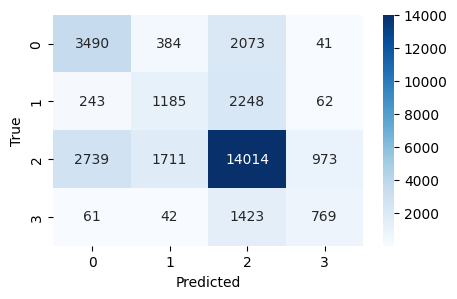

In [116]:
# Fine-tune CatBoost (best performing model)
def tune_catboost(df):
    """Fine-tune CatBoost with different hyperparameters"""
    
    print("\n" + "=" * 80)
    print("HYPERPARAMETER TUNING FOR CATBOOST")
    print("=" * 80)
    
    # Try different CatBoost configurations
    configs = [
        {'iterations': 300, 'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 3},
        {'iterations': 400, 'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 1},
        {'iterations': 250, 'depth': 10, 'learning_rate': 0.08, 'l2_leaf_reg': 5},
        {'iterations': 500, 'depth': 6, 'learning_rate': 0.02, 'l2_leaf_reg': 7},
        {'iterations': 350, 'depth': 9, 'learning_rate': 0.04, 'l2_leaf_reg': 2}
    ]
    
    best_config = None
    best_score = 0
    best_kappa = 0
    best_predictions = None
    
    print("Testing different CatBoost configurations...")
    
    for i, config in enumerate(configs, 1):
        print(f"\nConfig {i}/{len(configs)}: {config}")
        
        model = cb.CatBoostClassifier(
            auto_class_weights='Balanced',
            random_seed=42,
            verbose=False,
            **config
        )
        
        y_true, y_pred, _ = sgkf(model, df, show_eval=False)
        f1_score_val = f1_score(y_true, y_pred, average='macro')
        kappa_val = cohen_kappa_score(y_true, y_pred)
        
        print(f"F1-Score: {f1_score_val:.4f}, Kappa: {kappa_val:.4f}")
        
        if f1_score_val > best_score:
            best_score = f1_score_val
            best_kappa = kappa_val
            best_config = config
            best_predictions = (y_true, y_pred)
    
    print(f"\n" + "="*60)
    print("BEST CATBOOST CONFIGURATION")
    print("="*60)
    print(f"Best Config: {best_config}")
    print(f"Best F1-Score: {best_score:.4f}")
    print(f"Best Kappa: {best_kappa:.4f}")
    
    # Compare with original CatBoost
    original_score = f1_cat
    original_kappa = kappa_cat
    f1_improvement = best_score - original_score
    kappa_improvement = best_kappa - original_kappa
    
    print(f"\nComparison with original CatBoost:")
    print(f"Original F1: {original_score:.4f}, Tuned F1: {best_score:.4f}")
    print(f"Original Kappa: {original_kappa:.4f}, Tuned Kappa: {best_kappa:.4f}")
    print(f"F1 Improvement: {f1_improvement:+.4f}")
    print(f"Kappa Improvement: {kappa_improvement:+.4f}")
    
    # Show detailed performance of best model
    print(f"\n" + "="*60)
    print("DETAILED PERFORMANCE OF BEST CATBOOST")
    print("="*60)
    visualize_performance(best_predictions[0], best_predictions[1])
    
    return {
        'config': best_config,
        'f1_macro': best_score,
        'kappa': best_kappa,
        'predictions': best_predictions,
        'improvement_f1': f1_improvement,
        'improvement_kappa': kappa_improvement
    }

# Tune CatBoost
catboost_tuned = tune_catboost(df_temporal)

The model with the followign paramters turned out to be best:
+ iterations=350
+ depth=9
+ learning_rate=0.04
+ l2_leaf_reg=2

### Train and save best model

Having found a satisfying model we trained it on 90% of the subjects to get some final sleep stage plots to check how realistic the predictions are.

In [12]:
df = pd.read_csv('features_df_scaled.csv')
df["Sleep_Stage"] = df["Sleep_Stage"].map(SLEEP_STAGE_MAPPING)
df["Sleep_Stage"] = df["Sleep_Stage"].astype(int)
df_temporal = temporal_context_features(df)

In [13]:
# Split subjects into train/test (90/10 split)
unique_subjects = df_temporal['sid'].unique()
train_subjects, test_subjects = train_test_split(
    unique_subjects, 
    test_size=0.1, 
    random_state=1,
    stratify=None
)

# Create train/test datasets based on subject split
train_data = df_temporal[df_temporal['sid'].isin(train_subjects)].copy()
test_data = df_temporal[df_temporal['sid'].isin(test_subjects)].copy()

# Prepare features and labels
X_train = train_data[train_data.columns.difference(NOT_FEATURES)]
y_train = train_data["Sleep_Stage"]
X_test = test_data[test_data.columns.difference(NOT_FEATURES)]
y_test = test_data["Sleep_Stage"]

print(f"Train subjects: {len(train_subjects)} ({len(train_data)} samples)")
print(f"Test subjects: {len(test_subjects)} ({len(test_data)} samples)")
print(f"Train class distribution:\n{y_train.value_counts().sort_index()}")
print(f"Test class distribution:\n{y_test.value_counts().sort_index()}")

Train subjects: 35 (28233 samples)
Test subjects: 4 (3225 samples)
Train class distribution:
Sleep_Stage
0     5206
1     3355
2    17530
3     2142
Name: count, dtype: int64
Test class distribution:
Sleep_Stage
0     782
1     383
2    1907
3     153
Name: count, dtype: int64



Final Model Performance:
Cohen's Kappa: 0.2652642770352369
              precision    recall  f1-score   support

           0       0.57      0.46      0.51       782
           1       0.38      0.38      0.38       383
           2       0.67      0.70      0.68      1907
           3       0.17      0.22      0.19       153

    accuracy                           0.58      3225
   macro avg       0.45      0.44      0.44      3225
weighted avg       0.59      0.58      0.58      3225



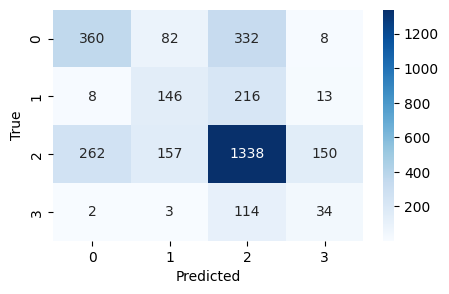

['best_catboost_model.pkl']

In [ ]:
# Train best CatBoost model (from hyperparameter tuning)
best_catboost = cb.CatBoostClassifier(
    iterations=350,
    depth=9,
    learning_rate=0.04,
    l2_leaf_reg=2,
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=False
)

best_catboost.fit(X_train, y_train)

y_pred = best_catboost.predict(X_test)

print("\nFinal Model Performance:")
visualize_performance(y_test, y_pred)

#joblib.dump(best_catboost, 'best_catboost_model.pkl')

## Feature importance

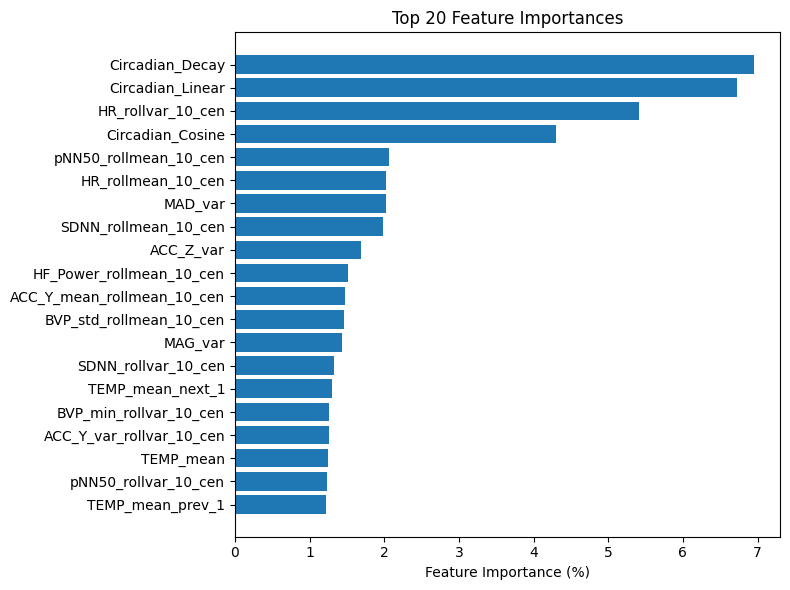

In [49]:
model = joblib.load('best_catboost_model.pkl')
plot_feature_importance(model, X_test.columns, top_n=20)

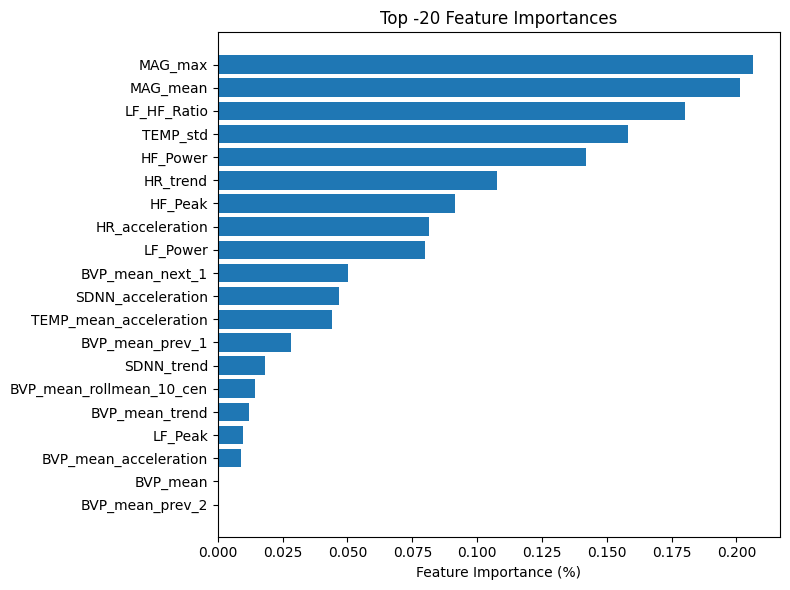

In [50]:
plot_feature_importance(model, X_test.columns, top_n=-20)

The feature analysis is interesting as some features for a single interval are almost not contributing to model performance at all, but the same feature for a larger window (HF_power) is very informative. That highlights the difficulty of extracting good features which we encountered.

## Postprocessing

We found out that numbers alone don’t tell the whole story. Thats why we also looked at the hypnogram (the sequence of predicted sleep stages over the night). Sleep usually has a structured architecture, and a predicition should reflect that. A realistic hypnogram typically shows more Deep NREM in the early part of the night, more REM toward the end, cycles of around 90 minutes, and smooth, plausible transitions between stages. We wanted to avoid unnatural patterns, like frequent short bursts of stages, direct jumps from Deep NREM to REM, or erratic switching that doesn’t match real sleep behavior.

These kinds of issues are hard to capture with metrics alone, so part of our model evaluation was visual and subjective: we simply looked at whether the predicted hypnogram made physiological sense. Becasue this isnt something the model an inforce directly we applied a postprocessing to the predictions of our final model.

In [51]:
def postprocess_predictions(predictions, min_duration=3, window_size=5):
    """
    Postprocessing for sleep stage predictions.
    
    Args:
        predictions: Array of predicted sleep stages
        min_duration: Minimum episode duration (in 30-sec epochs)
        window_size: Size of median filter window for smoothing
    """
    from scipy.stats import mode
    from scipy.ndimage import median_filter
    import numpy as np
    
    result = np.array(predictions.copy())
    
    # Step 1: Apply median filter for initial smoothing
    result = median_filter(result.astype(float), size=window_size).astype(int)
    
    # Step 2: Remove short episodes with smarter replacement logic
    result = remove_short_episodes(result, min_duration)
    
    # Step 3: Apply physiological constraints
    result = apply_sleep_rules(result)
    
    # Step 4: Final smoothing pass
    result = smooth_transitions(result)
    
    return result

def remove_short_episodes(predictions, min_duration):
    result = predictions.copy()
    
    # Process each stage type with different strategies
    stage_priorities = {
        0: 1,  # Wake - moderate priority
        1: 3,  # REM - high priority (preserve when possible)
        2: 2,  # Light NREM - medium priority
        3: 3   # Deep NREM - high priority (preserve when possible)
    }
    
    # Sort stages by priority (process low priority first)
    stages_to_process = sorted(stage_priorities.keys(), key=lambda x: stage_priorities[x])
    
    for stage in stages_to_process:
        result = remove_stage_episodes(result, stage, min_duration)
    
    return result

def remove_stage_episodes(predictions, target_stage, min_duration):
    result = predictions.copy()
    i = 0
    
    while i < len(result):
        if result[i] == target_stage:
            episode_start = i
            while i < len(result) and result[i] == target_stage:
                i += 1
            episode_length = i - episode_start
            
            if episode_length < min_duration:
                replacement = choose_replacement_stage(result, episode_start, i, target_stage)
                result[episode_start:i] = replacement
        else:
            i += 1
    
    return result

def choose_replacement_stage(predictions, start_idx, end_idx, target_stage):
    
    # Get surrounding context (look 3 epochs before/after)
    context_window = 3
    before_start = max(0, start_idx - context_window)
    after_end = min(len(predictions), end_idx + context_window)
    
    before_stages = predictions[before_start:start_idx] if start_idx > 0 else []
    after_stages = predictions[end_idx:after_end] if end_idx < len(predictions) else []
    
    # Strategy 1: If surrounded by same stage, bridge the gap
    if len(before_stages) > 0 and len(after_stages) > 0:
        before_mode = mode(before_stages)[0] if len(before_stages) > 0 else None
        after_mode = mode(after_stages)[0] if len(after_stages) > 0 else None
        
        if before_mode == after_mode:
            return before_mode
    
    # Strategy 2: Use the most common stage in surrounding context
    all_context = np.concatenate([before_stages, after_stages]) if len(before_stages) > 0 or len(after_stages) > 0 else []
    if len(all_context) > 0:
        context_mode = mode(all_context)[0]
        return context_mode
    
    # Strategy 3: Apply physiological defaults
    if target_stage == 0:  # Wake -> usually becomes Light NREM
        return 2
    elif target_stage == 1:  # REM -> usually becomes Light NREM
        return 2
    else:  # NREM stages -> use Light NREM as default
        return 2

def apply_sleep_rules(predictions):
    result = predictions.copy()
    
    # Rule 1: No REM in first 60 minutes (120 epochs)
    early_rem_mask = (result == 1) & (np.arange(len(result)) < 120)
    result[early_rem_mask] = 2
    
    # Rule 2: Deep sleep (stage 3) more likely in first half of night
    midpoint = len(result) // 2
    late_deep_mask = (result == 3) & (np.arange(len(result)) > midpoint * 1.5)
    # Convert some late deep sleep to light sleep (but not all)
    late_deep_indices = np.where(late_deep_mask)[0]
    if len(late_deep_indices) > 0:
        # Convert every other late deep sleep episode
        result[late_deep_indices[::2]] = 2
    
    # Rule 3: Limit direct transitions from Deep (3) to Wake (0)
    for i in range(len(result) - 1):
        if result[i] == 3 and result[i + 1] == 0:
            # Insert Light NREM as transition
            if i + 2 < len(result):
                result[i + 1] = 2
    
    return result

def smooth_transitions(predictions):
    result = predictions.copy()
    
    # Apply a conservative smoothing filter
    for i in range(1, len(result) - 1):
        prev_stage = result[i - 1]
        curr_stage = result[i]
        next_stage = result[i + 1]
        
        # If current stage is isolated and different from neighbors
        if prev_stage == next_stage and curr_stage != prev_stage:
            # Check if this creates a more natural transition
            if is_valid_transition(prev_stage, curr_stage) and is_valid_transition(curr_stage, next_stage):
                continue  # Keep the transition
            else:
                result[i] = prev_stage  # Smooth out the isolated stage
    
    return result

def is_valid_transition(from_stage, to_stage):
    # Define allowed transitions (more permissive than strict rules)
    allowed_transitions = {
        0: [0, 2],        # Wake -> Wake, Light NREM
        1: [0, 1, 2],     # REM -> Wake, REM, Light NREM  
        2: [0, 1, 2, 3],  # Light NREM -> any stage
        3: [2, 3]         # Deep NREM -> Light NREM, Deep NREM
    }
    
    return to_stage in allowed_transitions.get(from_stage, [])

## Visualizing Sleep Stage Predictions

In [52]:
best_catboost_loaded = joblib.load('best_catboost_model.pkl')
test_subject_data = df_temporal[df_temporal['sid'] == test_subjects[3]]
y_pred_subject = best_catboost_loaded.predict(test_subject_data[test_subject_data.columns.difference(NOT_FEATURES)])

In [ ]:
plot_hypnogram(test_subject_data['Sleep_Stage'].values.tolist(), test_subject_data['Interval'].values)

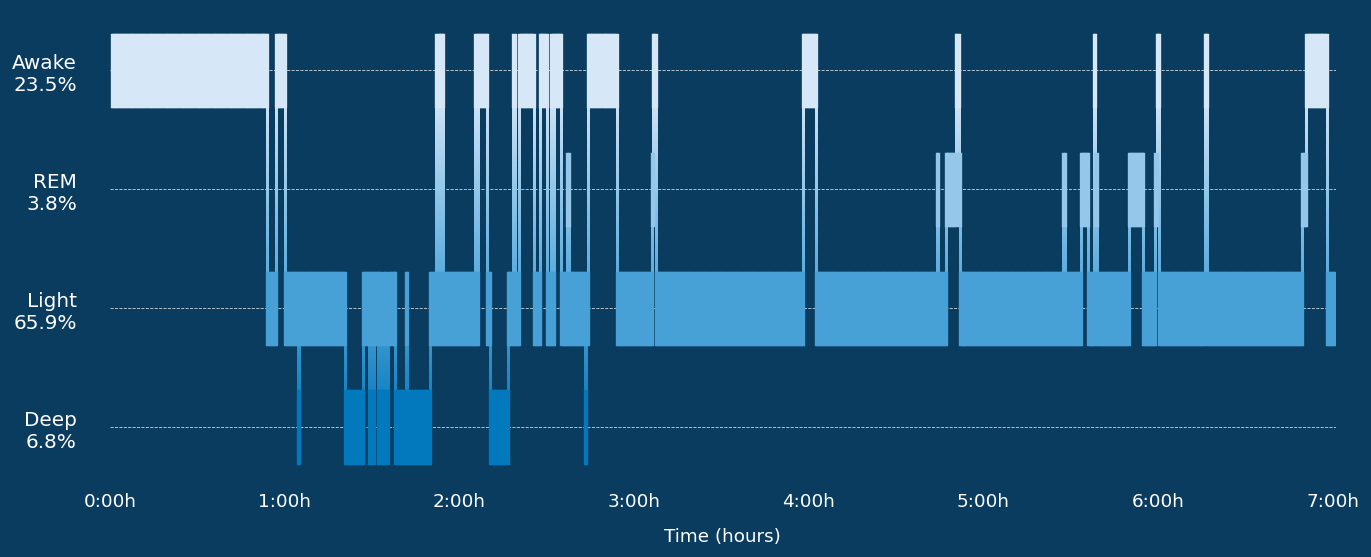

In [56]:
plot_hypnogram(y_pred_subject.flatten().tolist(), test_subject_data['Interval'].values)

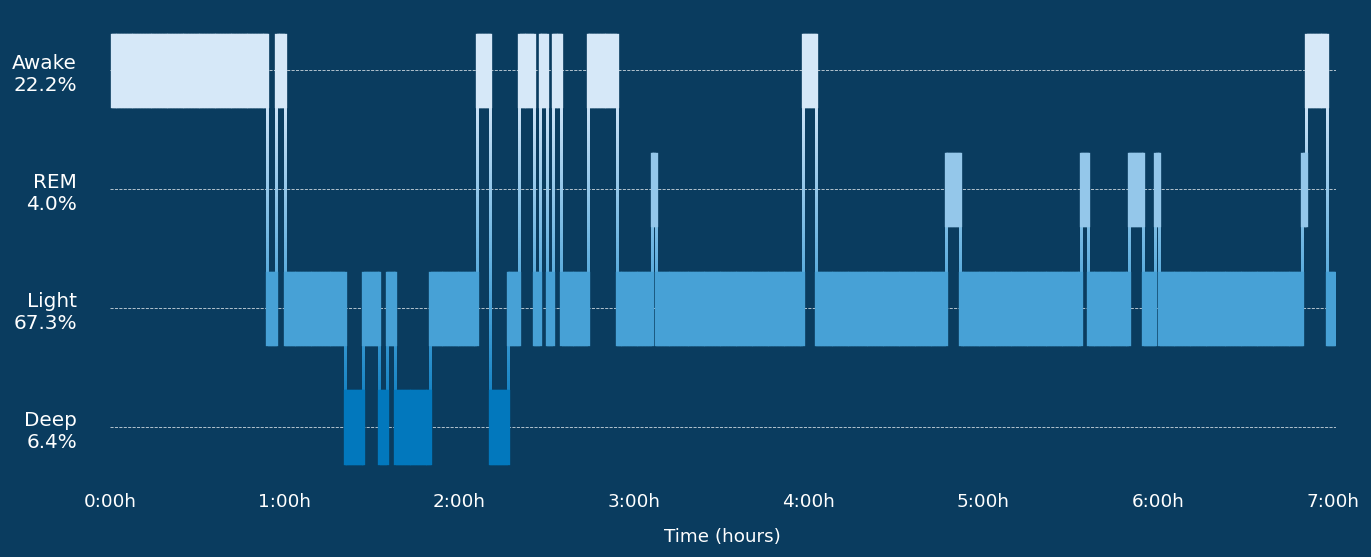

In [58]:
y_pred_smooth = postprocess_predictions(y_pred_subject.flatten().tolist(), min_duration=3, window_size=5)
plot_hypnogram(y_pred_smooth.flatten().tolist(), test_subject_data['Interval'].values)

## Conclusion

In this project, we aimed to classify sleep stages using data collected from wearable devices. Starting with the DREAMT dataset, we extracted features from multiple physiological modalities, including heart rate, temperature, accelerometer data, and circadian rhythms. To improve the model's ability to detect temporal dynamics and stage transitions, we engineered additional temporal and rolling features. We then evaluated several machine learning models, including LightGBM, Random Forest, XGBoost, and CatBoost. Among these, CatBoost delivered the best performance, possibly due to its robust handling of categorical features, class imbalance, and sequential patterns. Finally, we applied postprocessing techniques to smooth predictions and ensure that the resulting hypnograms better reflected known physiological sleep structures.

That said, the project proved to be more complex than we initially expected. Although we achieved moderate classification accuracy, the results were not as strong or consistent as we had hoped. The difficulty seemed to stem from a combination of factors: the inherent complexity of sleep stage classification, variability and potential noise in the wearable data, and limitations in our feature engineering. In particular, we noticed that the ground truth labels appeared somewhat unrealistic for some subjects—showing abrupt and frequent stage transitions that don’t align well with typical sleep architecture, even though the data was annotated by professionals. This raised doubts about the reliability of the dataset in certain cases.

Despite these obstacles, seeing the final hypnograms after postprocessing was rewarding—they looked surprisingly realistic and much closer to what we’d expect from actual sleep data. It was a reassuring moment that showed our approach had some merit, even if the performance metrics didn’t fully reflect it.

Overall, this project was a valuable learning experience. It pushed us to think critically about modeling time-dependent physiological data, the nuances of sleep science, and the practical challenges of working with real-world wearable datasets. There’s definitely room for improvement, especially in feature extraction and label validation, but we’re proud of the progress we made and the insights we gained along the way.

### References

[1] Wang, W. K., Yang, J., Hershkovich, L., Jeong, H., Chen, B., Singh, K., ... & Dunn, J. (2024, July). *Addressing wearable sleep tracking inequity: A new dataset and novel methods for a population with sleep disorders*. In Proceedings of the Fifth Conference on Health, Inference, and Learning (Proceedings of Machine Learning Research, Vol. 248, pp. 380–396). Edited by Tom Pollard, Edward Choi, Pankhuri Singhal, Michael Hughes, Elena Sizikova, Bobak Mortazavi, Irene Chen, Fei Wang, Tasmie Sarker, Matthew McDermott, and Marzyeh Ghassemi. PMLR.

[2] Djanian, S., Bruun, A., & Nielsen, T. D. (2022). *Sleep classification using consumer sleep technologies and AI: A review of the current landscape*. Sleep Medicine, 100, 390–403.

[3] Altini, M., & Kinnunen, H. (2021). *The promise of sleep: A multi-sensor approach for accurate sleep stage detection using the Oura Ring*. Sensors, 21(13), 4302.